In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

df = pd.read_excel(r"C:\Customer Churn Predictor\data\raw\Telco_customer_churn.xlsx")

df.head()



,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
df.info()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [3]:
df.head()
df.describe(include="all")
df.nunique()

CustomerID           7043
Count                   1
Country                 1
State                   1
City                 1129
Zip Code             1652
Lat Long             1652
Latitude             1652
Longitude            1651
Gender                  2
Senior Citizen          2
Partner                 2
Dependents              2
Tenure Months          73
Phone Service           2
Multiple Lines          3
Internet Service        3
Online Security         3
Online Backup           3
Device Protection       3
Tech Support            3
Streaming TV            3
Streaming Movies        3
Contract                3
Paperless Billing       2
Payment Method          4
Monthly Charges      1585
Total Charges        6531
Churn Label             2
Churn Value             2
Churn Score            85
CLTV                 3438
Churn Reason           20
dtype: int64

In [4]:
#data quality
df.isnull().sum()
df.duplicated().sum()
df["Churn Label"].value_counts()
df["Total Charges"].dtype


dtype('O')

In [5]:
#inpection 
df["Total Charges"].head(10)

df["Total Charges"].unique()[:20]

df[df["Total Charges"]==" "]

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,...,Two year,Yes,Bank transfer (automatic),52.55,,No,0,36,2578,NaN
2438,3115-CZMZD,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,...,Two year,No,Mailed check,20.25,,No,0,68,5504,NaN
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,...,Two year,No,Mailed check,80.85,,No,0,45,2048,NaN
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,...,Two year,No,Mailed check,25.75,,No,0,48,4950,NaN
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,...,Two year,No,Credit card (automatic),56.05,,No,0,30,4740,NaN
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,...,Two year,No,Mailed check,19.85,,No,0,53,2019,NaN
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,...,Two year,No,Mailed check,25.35,,No,0,49,2299,NaN
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,...,Two year,No,Mailed check,20.00,,No,0,27,3763,NaN
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,...,One year,Yes,Mailed check,19.70,,No,0,69,4890,NaN
6772,4075-WKNIU,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,...,Two year,No,Mailed check,73.35,,No,0,44,2342,NaN


In [6]:
df.isnull().sum()


CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df_clean = df.copy()

In [9]:
columns_to_drop = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Score",
    "CLTV",
    "Churn Reason"
]

df_clean = df_clean.drop(columns = columns_to_drop)

In [10]:
df_clean.shape

(7043, 22)

In [11]:
df_clean.columns

Index(['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label',
       'Churn Value'],
      dtype='object')

In [12]:
df_clean["Total Charges"] = pd.to_numeric(
    df_clean["Total Charges"],
    errors="coerce"
)

In [13]:
df_clean["Total Charges"].dtype

dtype('float64')

In [14]:
df_clean["Total Charges"].isnull().sum()

np.int64(11)

In [15]:
missing_percentage = (df_clean["Total Charges"].isnull().sum()/len(df_clean)) * 100

print(missing_percentage)


0.1561834445548772


In [16]:
df_clean = df_clean.dropna(subset = ["Total Charges"])

In [17]:
df_clean.to_csv(
    r"C:\Customer Churn Predictor\data\raw\Telco_customer_churn.csv",
    index=False
)

In [18]:
df_clean["Churn Value"].value_counts()

Churn Value
0    5163
1    1869
Name: count, dtype: int64

In [19]:
df_clean["Churn Value"].value_counts(normalize=True) * 100


Churn Value
0    73.421502
1    26.578498
Name: proportion, dtype: float64

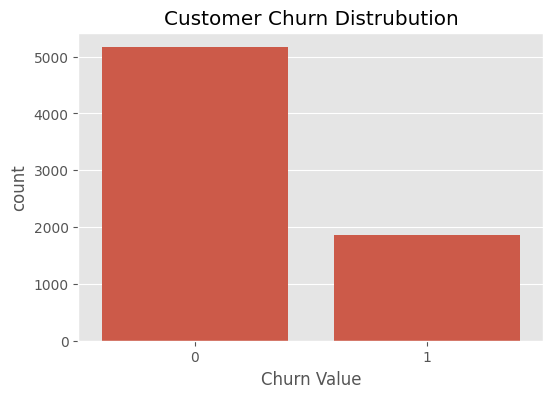

In [20]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Churn Value",
    data = df_clean
)
plt.title("Customer Churn Distrubution")
plt.show()

In [21]:
pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn Label"]
)

Churn Label,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


In [22]:
pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.722826,11.277174
Two year,97.151335,2.848665


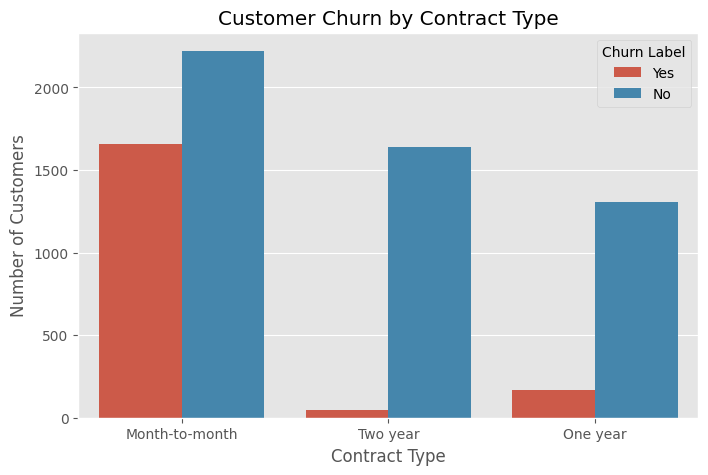

In [23]:
plt.figure(figsize=(8,5))

sns.countplot(
    data = df_clean,
    x="Contract",
    hue="Churn Label"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

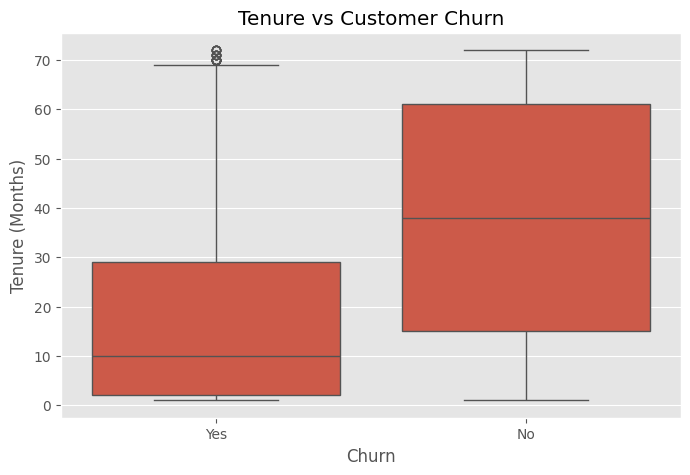

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data = df_clean,
    x="Churn Label",
    y="Tenure Months"
)

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

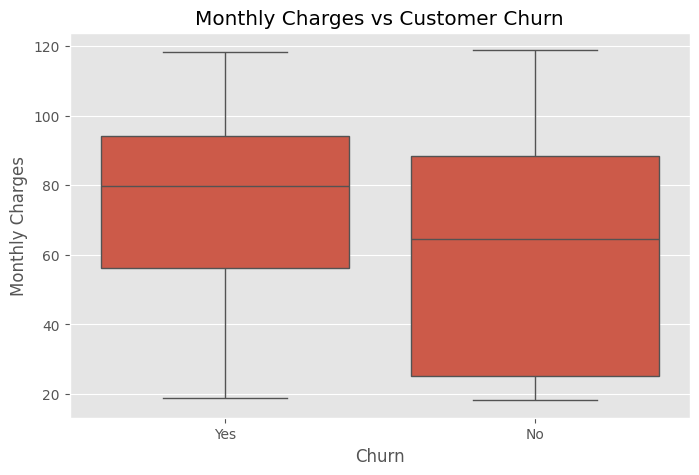

In [25]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="Churn Label",
    y="Monthly Charges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [26]:
pd.crosstab(
    df_clean["Internet Service"],
    df_clean["Churn Label"]
)

Churn Label,No,Yes
Internet Service,,
DSL,1957,459
Fiber optic,1799,1297
No,1407,113


In [27]:
pd.crosstab(
    df_clean["Internet Service"],
    df_clean["Churn Label"],
    normalize = "index"
) * 100

Churn Label,No,Yes
Internet Service,,
DSL,81.001656,18.998344
Fiber optic,58.107235,41.892765
No,92.565789,7.434211


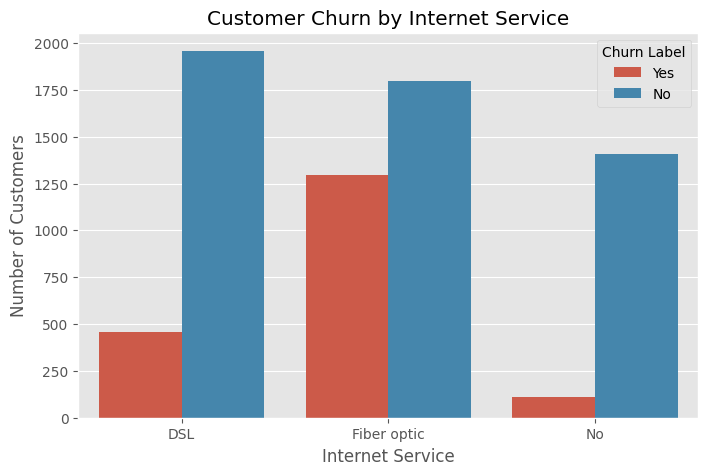

In [28]:
plt.figure(figsize=(8,5))

sns.countplot(
    data = df_clean,
    x="Internet Service",
    hue="Churn Label"
)
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [29]:
numeric_df = df_clean.select_dtypes(include=["int64","float64"])
corr = numeric_df.corr()

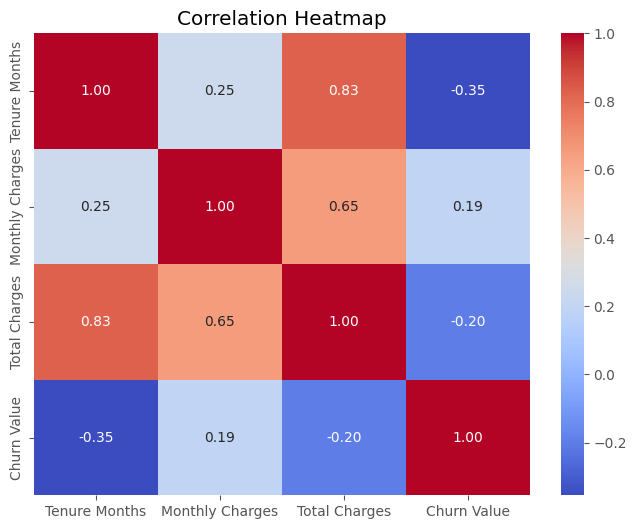

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot = True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [31]:
X = df_clean.drop(columns = ["Churn Value","Churn Label"])

y = df_clean["Churn Value"]

In [32]:
X.shape
y.shape

(7032,)

In [33]:
X.dtypes

City                  object
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
dtype: object

In [34]:
X = X.drop(columns = ["City"])


In [35]:
X.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges'],
      dtype='object')

In [36]:
categorical_features = X.select_dtypes(include=["object"]).columns

numerical_features = X.select_dtypes(include=["int64","float64"]).columns

print("Categorical Features : ")
print(categorical_features)
print("\n Numerical features")
print(numerical_features)


Categorical Features : 
Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object')

 Numerical features
Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='object')


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [38]:
preprocessor = ColumnTransformer(
    transformers = [
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
        ]
)

In [39]:
from sklearn.model_selection import train_test_split



In [40]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42,stratify = y)


In [41]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(5625, 19)
(1407, 19)
(5625,)
(1407,)


In [42]:
from sklearn.linear_model import LogisticRegression


In [43]:
model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(random_state=42))
    ]
)

In [44]:
model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [45]:
y_pred = model.predict(X_test)

In [46]:
print(y_pred[:10])

[0 1 0 0 0 0 0 0 1 0]


In [47]:
print("Predictions:")
print(y_pred[:10])

print("\nActual:")
print(y_test[:10].values)

Predictions:
[0 1 0 0 0 0 0 0 1 0]

Actual:
[0 0 0 1 0 1 0 0 1 0]


In [48]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [49]:
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy : ",accuracy)

Accuracy :  0.8045486851457001


In [50]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[907 126]
 [149 225]]


In [51]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.88      0.87      1033
           1       0.64      0.60      0.62       374

    accuracy                           0.80      1407
   macro avg       0.75      0.74      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [52]:
from sklearn.tree import DecisionTreeClassifier

In [53]:
decision_tree = Pipeline(
    steps = [
        ("preprocessor",preprocessor),
        ("classifier",DecisionTreeClassifier(random_state=42))
    ]
)

In [54]:
decision_tree.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [55]:
dt_pred = decision_tree.predict(X_test)

In [56]:
print("Accuracy : ",accuracy_score(y_test,dt_pred))

print("\n",classification_report(y_test,dt_pred))


Accuracy :  0.7292110874200426

               precision    recall  f1-score   support

           0       0.81      0.82      0.82      1033
           1       0.49      0.49      0.49       374

    accuracy                           0.73      1407
   macro avg       0.65      0.65      0.65      1407
weighted avg       0.73      0.73      0.73      1407



In [57]:
from sklearn.ensemble import RandomForestClassifier

In [58]:
random_forest = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

In [59]:
random_forest.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [60]:
rf_pred = random_forest.predict(X_test)

In [61]:
print("Accuracy:", accuracy_score(y_test, rf_pred))

print(classification_report(y_test, rf_pred))

Accuracy: 0.7924662402274343
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



In [62]:
#Hyperperameter tuning

from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators":[50,100,200],
    "classifier__max_depth": [5,10,None],
    "classifier__min_samples_split": [2,5]
}

In [63]:
grid_search = GridSearchCV(
    estimator=random_forest,
    param_grid=param_grid,
    cv = 5,
    scoring="f1",
    n_jobs=-1
)

In [64]:
grid_search.fit(X_train,y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [50, 100, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [65]:
print(grid_search.best_params_)

{'classifier__max_depth': 10, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}


In [66]:
print(grid_search.best_score_)

0.6029793140324149


In [67]:
best_model = grid_search.best_estimator_

In [68]:
best_pred = best_model.predict(X_test)

In [69]:
print("Accuracy:", accuracy_score(y_test, best_pred))

print(classification_report(y_test, best_pred))

Accuracy: 0.8002842928216063
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.64      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.75      0.72      0.73      1407
weighted avg       0.79      0.80      0.80      1407



In [77]:
import shap

print(shap.__version__)

0.49.1


In [78]:
x_test_preprocessor = preprocessor.transform(X_test)

In [79]:
classifier = model.named_steps["classifier"]

In [80]:
X_test_processed = model.named_steps["preprocessor"].transform(X_test)

In [83]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()


In [84]:
print(feature_names[:20])

['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'cat__Gender_Female' 'cat__Gender_Male' 'cat__Senior Citizen_No'
 'cat__Senior Citizen_Yes' 'cat__Partner_No' 'cat__Partner_Yes'
 'cat__Dependents_No' 'cat__Dependents_Yes' 'cat__Phone Service_No'
 'cat__Phone Service_Yes' 'cat__Multiple Lines_No'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_DSL' 'cat__Internet Service_Fiber optic'
 'cat__Internet Service_No' 'cat__Online Security_No']


In [86]:
X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

In [87]:
explainer = shap.LinearExplainer(
    classifier,
    X_test_processed_df
)

In [88]:
shap_values = explainer(X_test_processed_df)

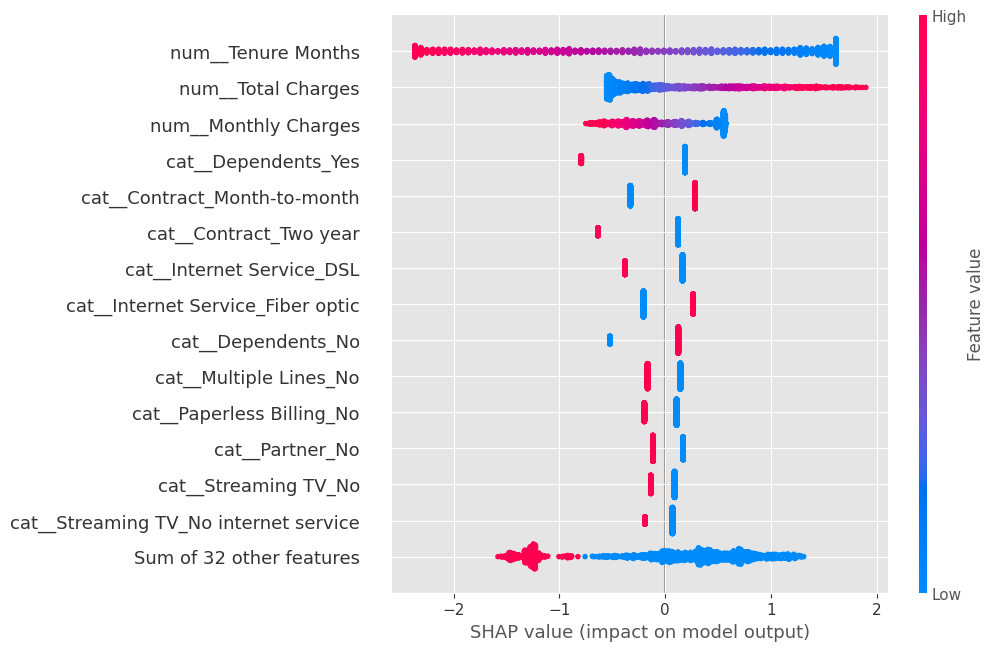

In [91]:
shap.plots.beeswarm(shap_values,max_display=15)

In [93]:
customer_index = 0

X_test.iloc[customer_index]

Gender                                Female
Senior Citizen                            No
Partner                                  Yes
Dependents                                No
Tenure Months                             59
Phone Service                            Yes
Multiple Lines                            No
Internet Service                         DSL
Online Security                           No
Online Backup                            Yes
Device Protection                         No
Tech Support                             Yes
Streaming TV                             Yes
Streaming Movies                         Yes
Contract                            Two year
Paperless Billing                        Yes
Payment Method       Credit card (automatic)
Monthly Charges                        75.95
Total Charges                        4542.35
Name: 2595, dtype: object

In [94]:
prediction = model.predict(X_test.iloc[[customer_index]])
probability = model.predict_proba(X_test.iloc[[customer_index]])

print("Prediction:", prediction[0])
print("Probability:", probability)

Prediction: 0
Probability: [[0.96766392 0.03233608]]


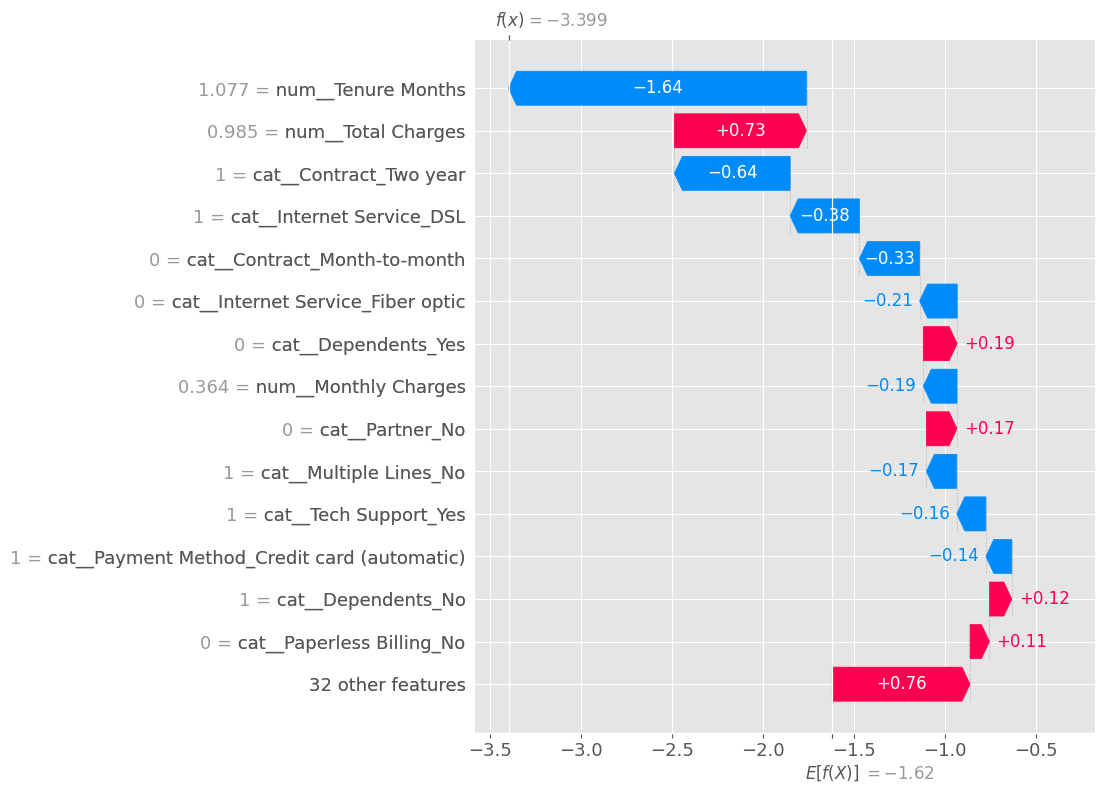

In [95]:
shap.plots.waterfall(shap_values[customer_index], max_display=15)

In [96]:
import pickle

In [97]:
with open("../models/churn_model.pkl", "wb") as file:
    pickle.dump(model, file)

In [98]:
with open("../models/feature_names.pkl", "wb") as file:
    pickle.dump(feature_names, file)

In [99]:
with open("../models/churn_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

In [101]:
prediction = loaded_model.predict(X_test.iloc[[0]])

print(prediction)

if prediction[0] == 1:
    print("Prediction: Customer will Churn")
else:
    print("Prediction: Customer will NOT Churn")

[0]
Prediction: Customer will NOT Churn


In [102]:
probability = loaded_model.predict_proba(X_test.iloc[[0]])

print(probability)

[[0.96766392 0.03233608]]


In [104]:
probability = loaded_model.predict_proba(X_test.iloc[[0]])

stay_prob = probability[0][0]
churn_prob = probability[0][1]

print(f"Stay Probability : {stay_prob:.2%}")
print(f"Churn Probability: {churn_prob:.2%}")

Stay Probability : 96.77%
Churn Probability: 3.23%
